In [1]:
from uproot_methods import TVector2Array, TLorentzVectorArray
from optparse import OptionParser
from coffea.jetmet_tools import FactorizedJetCorrector, JetCorrectionUncertainty, JetTransformer, JetResolution, JetResolutionScaleFactor
from coffea.util import load, save
from coffea import hist, processor
from coffea.arrays import Initialize
import lz4.frame as lz4f
import cloudpickle
import json
import pprint
import numpy as np
import math
import awkward
np.seterr(divide='ignore', invalid='ignore', over='ignore')
import time

In [2]:
import awkward as ak
from coffea.nanoaod.nanoevents import NanoEvents

# fnameUL = "root://xrootd-cms.infn.it//store/mc/RunIISummer20UL18NanoAODv9/DYJetsToLL_M-50_HT-400to600_TuneCP5_PSweights_13TeV-madgraphMLM-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/4F3BA45A-907E-9846-AECE-578D2AF50F44.root"
# fnameL = 'root://cmseos.fnal.gov//store/group/lpccoffea/coffeabeans/NanoAODv6/nano_2018/TTJets_TuneCP5_13TeV-amcatnloFXFX-pythia8/NanoTuples-2018_RunIIAutumn18MiniAOD-102X_v15-v2-ext1/191208_161323/0002/nano_2015.root'

# eventsL = NanoEvents.from_file(fnameL)

# fnameUL =  "root://cmsxrootd.fnal.gov//store/data/Run2018D/EGamma/NANOAOD/UL2018_MiniAODv1_NanoAODv2-v2/130000/1DDDC254-5078-F44D-AB98-F669859E8A72.root"
# eventsUL = NanoEvents.from_file(fnameUL)


fnameMC = "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root"
eventsMC = NanoEvents.from_file(fnameMC)

In [3]:
Gen = eventsMC.GenPart

In [20]:
remove_overlap = (Gen[Gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(Gen.pdgId) == 24))].pt < 200).all()


In [60]:
remove_overlap

array([ True,  True,  True, ...,  True,  True,  True])

In [61]:
Gen[remove_overlap].pt.max()

array([118.25, 136.  , 150.  , ..., 158.  , 107.  , 130.  ], dtype=float32)

In [5]:
Gen.pt[remove_overlap]

<JaggedArray [[0.0 0.0 118.25 ... 92.75 19.0625 13.59375] [0.0 0.0 117.5 ... 11.09375 0.12426758 0.052612305] [0.0 0.0 150.0 ... 31.1875 14.84375 16.3125] ... [0.0 0.0 135.0 ... 3.2265625 0.047973633 0.049072266] [0.0 0.0 106.25 ... 0.041625977 0.16455078 13.0625] [0.0 0.0 102.25 ... 0.021362305 0.015258789 0.0016670227]] at 0x7f9700a4d438>

array([False, False,  True, False, False,  True,  True,  True,  True,
        True, False, False, False, False, False, False, False, False,
       False])

In [32]:
len(Gen[Gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(Gen.pdgId) == 24))].pt.sum())

133026

In [21]:
len(Gen[Gen.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(Gen.pdgId) == 24))].pt)

133026

In [29]:
g = Gen[remove_overlap]


In [39]:
g[  ((abs(g.pdgId) == 24))].pt

<JaggedArray [[118.25 92.5 91.25 93.25 93.25 93.0] [117.5 127.5 133.5 133.5 129.5 130.0] [150.0 135.0 135.5 ... 135.5 135.5 136.5] ... [135.0 134.0 132.5 133.0 134.5] [106.25 105.25 105.75 107.0] [102.25 110.5 106.25 106.5 106.5 107.25]] at 0x7f96e94d9438>

In [25]:
Gen[remove_overlap].pt

<JaggedArray [[0.0 0.0 118.25 ... 92.75 19.0625 13.59375] [0.0 0.0 117.5 ... 11.09375 0.12426758 0.052612305] [0.0 0.0 150.0 ... 31.1875 14.84375 16.3125] ... [0.0 0.0 135.0 ... 3.2265625 0.047973633 0.049072266] [0.0 0.0 106.25 ... 0.041625977 0.16455078 13.0625] [0.0 0.0 102.25 ... 0.021362305 0.015258789 0.0016670227]] at 0x7f9700840860>

In [40]:
m=eventsMC.Muon
m.pt

<JaggedArray [[] [9.088903] [9.947318] ... [] [] []] at 0x7f96e94d9be0>

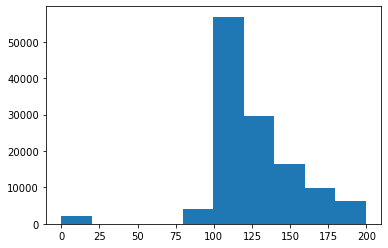

In [35]:
import matplotlib.pyplot as plt
plt.hist(g[g.hasFlags(['fromHardProcess', 'isFirstCopy', 'isPrompt']) & ((abs(g.pdgId) == 24))].pt.sum())
plt.show()

In [38]:
m.pt

<JaggedArray [[] [9.088903] [9.947318] ... [] [] []] at 0x7f97009d7e10>